# 1. Two low-mass X-ray binaries: the systems and their echoes

An X-ray interferometer with the bundled 10-baseline array (baselines 0.05-1 m, beam ~190 µas) cannot resolve a low-mass X-ray binary, but it still collects their photons with good timing. Here we set up the two systems of this study, GRS 1915+105 (black hole) and Cyg X-2 (neutron star), and show what the donor's reflection does in time: it echoes the corona's variability with a delay that changes around the orbit.

For a donor at distance r from the compact object, the echo arrives (r/c)(1 - sin i cos 2πφ) after the direct light, with φ = 0 at superior conjunction of the compact object. Measuring how the delay changes with phase gives a sin i in light-seconds, without resolving anything.

Both systems are built with `xrimodel`'s `XRBinary` without a donor wind: a Roche-lobe-filling donor, a flared outer disc and a point-like corona (`lmxrbs_xri.targets` lists the parameters and references). All spectra are unabsorbed unless stated.

In [1]:
import warnings

import numpy as np
import matplotlib.pyplot as plt

import xrimodel as xm
from xrimodel.engine import build_spectrum
from xrisalis import recipes

from lmxrbs_xri import CYGX2, GRS1915
from lmxrbs_xri.timing import band_rates, predicted_ccf

warnings.filterwarnings("ignore", message=".*electron-scattering optical depth.*")
SETUP = recipes.bundled()


def area(e):
    # the bundled ARF summed over baselines (cm^2)
    return np.interp(e, SETUP.arf.energy_mid, SETUP.arf.total, left=0, right=0)


TARGETS = (GRS1915, CYGX2)
VAR = {"grs": "broadband", "cx2": "high"}
FE = (5.9, 7.0)        # keV: the band richest in reflected light
REF = {"grs": (3.0, 5.0), "cx2": (1.0, 4.0)}   # reference bands (GRS 1915+105 is absorbed below ~2 keV)

 Solar Abundance Vector set to angr:  Anders E. & Grevesse N. Geochimica et Cosmochimica Acta 53, 197 (1989)
 Cross Section Table set to vern:  Verner, Ferland, Korista, and Yakovlev 1996


## Sizes on the sky and in light-seconds

Here we show the scales that matter: the separation a, the donor's radius and the compact object's Roche lobe (which bounds the disc), against the ~190 µas beam. Both systems are 4-30 times smaller than the beam; only the light-travel times (one to four minutes across the orbit) are comfortably measurable.

In [2]:
rows = []
for t in TARGETS:
    s = t.scales()
    rows.append((t.label, s["a_uas"], s["a_light_s"], s["r_donor_uas"], s["roche_lobe_compact_uas"],
                 s["roche_lobe_compact_rg"], s["disc_out_uas"]))
print(f"{'':14s}{'a (uas)':>9s}{'a/c (s)':>9s}{'R_donor':>9s}{'R_L,co':>9s}{'R_L,co (r_g)':>14s}{'R_disc':>9s}")
for r in rows:
    print(f"{r[0]:14s}{r[1]:9.1f}{r[2]:9.0f}{r[3]:9.1f}{r[4]:9.1f}{r[5]:14.2e}{r[6]:9.1f}")

                a (uas)  a/c (s)  R_donor   R_L,co  R_L,co (r_g)   R_disc
GRS 1915+105       49.4      232      7.8     31.7      2.70e+06     23.5
Cyg X-2            16.5       59      4.8      7.8      3.32e+06      6.1


## Spectra

Here we show each system's components: the corona (the illuminator, which varies), the disc's thermal emission with the broad inner-disc Fe line (constant here), and the total after interstellar absorption. GRS 1915+105 is in its historic bright state (Dhaka et al. 2024) behind N_H = 4.2×10²² cm⁻², so its reference band starts at 3 keV; Cyg X-2 is Comptonisation-dominated (Zhang et al. 2025). The bundled ARF's effective area (right axis) falls steeply above a few keV, where the Fe line is.

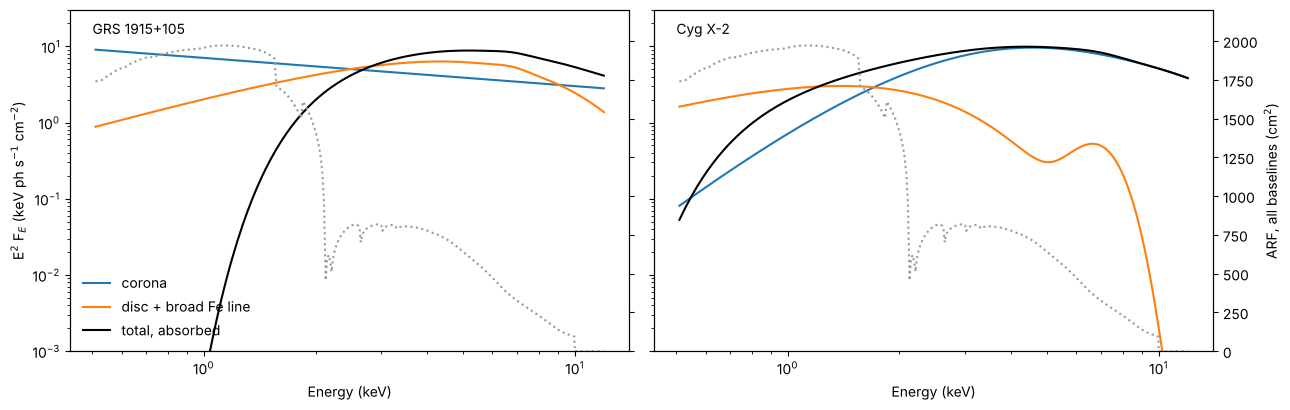

In [3]:
e = xm.energy_grid(0.5, 12.0, 0.02)
ec = 0.5 * (e[1:] + e[:-1])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for a, t in zip(ax, TARGETS):
    cor, disc = build_spectrum(t.corona, e), build_spectrum(t.disc, e)
    absorb = np.exp(-t.nh_ism * xm.format.spectra.sigma_photoabs(ec))
    a.loglog(ec, ec**2 * cor.values, label="corona")
    a.loglog(ec, ec**2 * disc.values, label="disc + broad Fe line")
    a.loglog(ec, ec**2 * (cor.values + disc.values) * absorb, "k", label="total, absorbed")
    a.set_xlabel("Energy (keV)")
    a.text(0.04, 0.93, t.label, transform=a.transAxes)
    a.set_ylim(1e-3, 30)
    a2 = a.twinx()
    a2.semilogx(ec, area(ec), color="0.6", ls=":")
    a2.set_ylim(0, 2200)
    if a is ax[1]:
        a2.set_ylabel("ARF, all baselines (cm$^2$)")
    else:
        a2.set_yticklabels([])
ax[0].set_ylabel("E$^2$ F$_E$ (keV ph s$^{-1}$ cm$^{-2}$)")
ax[0].legend(frameon=False, loc="lower left")
fig.tight_layout()

## The donor's reflection around the orbit

Here we render each system at 16 phases and show the donor's reflected flux relative to the corona (in all photons and in the Fe band) and its flux-weighted delay, with the delay range across the lit face. The dashed curve is (a/c)(1 - sin i cos 2πφ) for the donor's centre; the reflection comes from the face looking at the compact object, so it arrives a little earlier. The disc's reflection does not change with phase.

Compton reflection from neutral medium.
See help for details.
If you use results of this model in a paper,
please refer to Magdziarz & Zdziarski 1995 MNRAS, 273, 837


GRS 1915+105: disc reflection 2.65% of the corona at every phase
Cyg X-2: disc reflection 2.69% of the corona at every phase


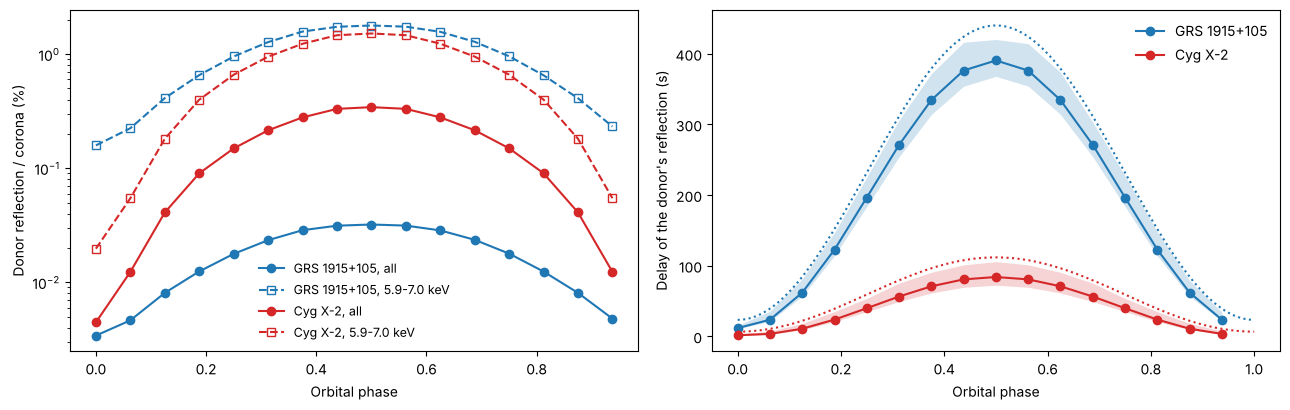

In [4]:
phases = np.linspace(0.0, 1.0, 17)[:-1]
models = {t.name: {} for t in TARGETS}
orbit = {}
for t in TARGETS:
    rows = []
    for ph in phases:
        m = t.scene(ph, VAR[t.name]).render()
        models[t.name][ph] = m
        cor = m.layer(f"{t.name}_corona")
        star, disc = m.layer(f"{t.name}_star"), m.layer(f"{t.name}_disc")
        fe = np.array(FE)
        f_fe = xm.specmap_projection(star, edges=fe)[0].values[0] / xm.specmap_projection(cor, edges=fe)[0].values[0]
        w = star.maps["NORM"]
        d = star.maps["DELAY"][w > 0]
        rows.append((ph, star.mean_photon_flux() / cor.mean_photon_flux(), f_fe,
                     np.sum(w * star.maps["DELAY"]) / w.sum(), d.min(), d.max(),
                     disc.mean_photon_flux() / cor.mean_photon_flux()))
    orbit[t.name] = np.array(rows)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for t, col in zip(TARGETS, ("C0", "C3")):
    r = orbit[t.name]
    ax[0].semilogy(r[:, 0], 100 * r[:, 1], "o-", color=col, label=f"{t.label}, all")
    ax[0].semilogy(r[:, 0], 100 * r[:, 2], "s--", color=col, mfc="none", label=f"{t.label}, {FE[0]}-{FE[1]} keV")
    ax[1].plot(r[:, 0], r[:, 3], "o-", color=col, label=t.label)
    ax[1].fill_between(r[:, 0], r[:, 4], r[:, 5], color=col, alpha=0.2, lw=0)
    s = t.scales()
    pf = np.linspace(0, 1, 200)
    ax[1].plot(pf, s["a_light_s"] * (1 - np.sin(np.radians(t.inclination)) * np.cos(2 * np.pi * pf)),
               ":", color=col)
    print(f"{t.label}: disc reflection {100 * r[:, 6].mean():.2f}% of the corona at every phase")
ax[0].set_xlabel("Orbital phase"); ax[0].set_ylabel("Donor reflection / corona (%)")
ax[0].legend(frameon=False, fontsize=9)
ax[1].set_xlabel("Orbital phase"); ax[1].set_ylabel("Delay of the donor's reflection (s)")
ax[1].legend(frameon=False)
fig.tight_layout()

Cyg X-2's donor returns ten times more of the corona's photons than GRS 1915+105's: its donor (a 7.5 R☉ A9 giant) fills a larger part of the orbit (Roche lobe 0.29a against 0.16a). In the Fe band the two are alike, 1.5-1.8% of the corona at phase 0.5, because the reflected spectrum is hard: GRS 1915+105's steep power law puts most of its photons below a few keV, where the donor absorbs rather than reflects them.

## On the sky: the models and their reconstructions

Before turning to time, here we show what there is to see and what the bundled array makes of it, at phase 0.5 when the donor's lit face is towards us. The left column shows the model on a fine grid: the reflected light (donor and disc, top) and the donor's reflection alone (bottom); the corona and the thermal disc are points at the compact object (cyan cross) and are left out of these panels. The donor's centre is the green cross.

The middle column shows XRISALIS reconstructions at the systems' real brightness: all the light (top, 100-200 s) and the donor's reflection alone (bottom, 100 ks for GRS 1915+105 and 20 ks for Cyg X-2), from the detected energies with `reconstruct`'s deconvolution, on 15 µas pixels. The right column is the model convolved with the dirty beam of a point source with the same spectrum, reconstructed the same way. Each panel is normalised to its own peak, and the donor alone is of course not separable from the corona in a real observation.

GRS 1915+105: donor centre (13.9, -16.6) uas, its reflection centred at (14.5, -17.3) uas
  all light: 419876 events; peak centroid (3, -1) uas reconstructed, (-0, 0) uas predicted
  donor alone: 243757 events; peak centroid (12, -15) uas reconstructed, (17, -13) uas predicted


Cyg X-2: donor centre (7.6, 0.0) uas, its reflection centred at (6.6, -0.0) uas
  all light: 676330 events; peak centroid (-1, 1) uas reconstructed, (0, -0) uas predicted
  donor alone: 133263 events; peak centroid (7, 0) uas reconstructed, (6, 1) uas predicted


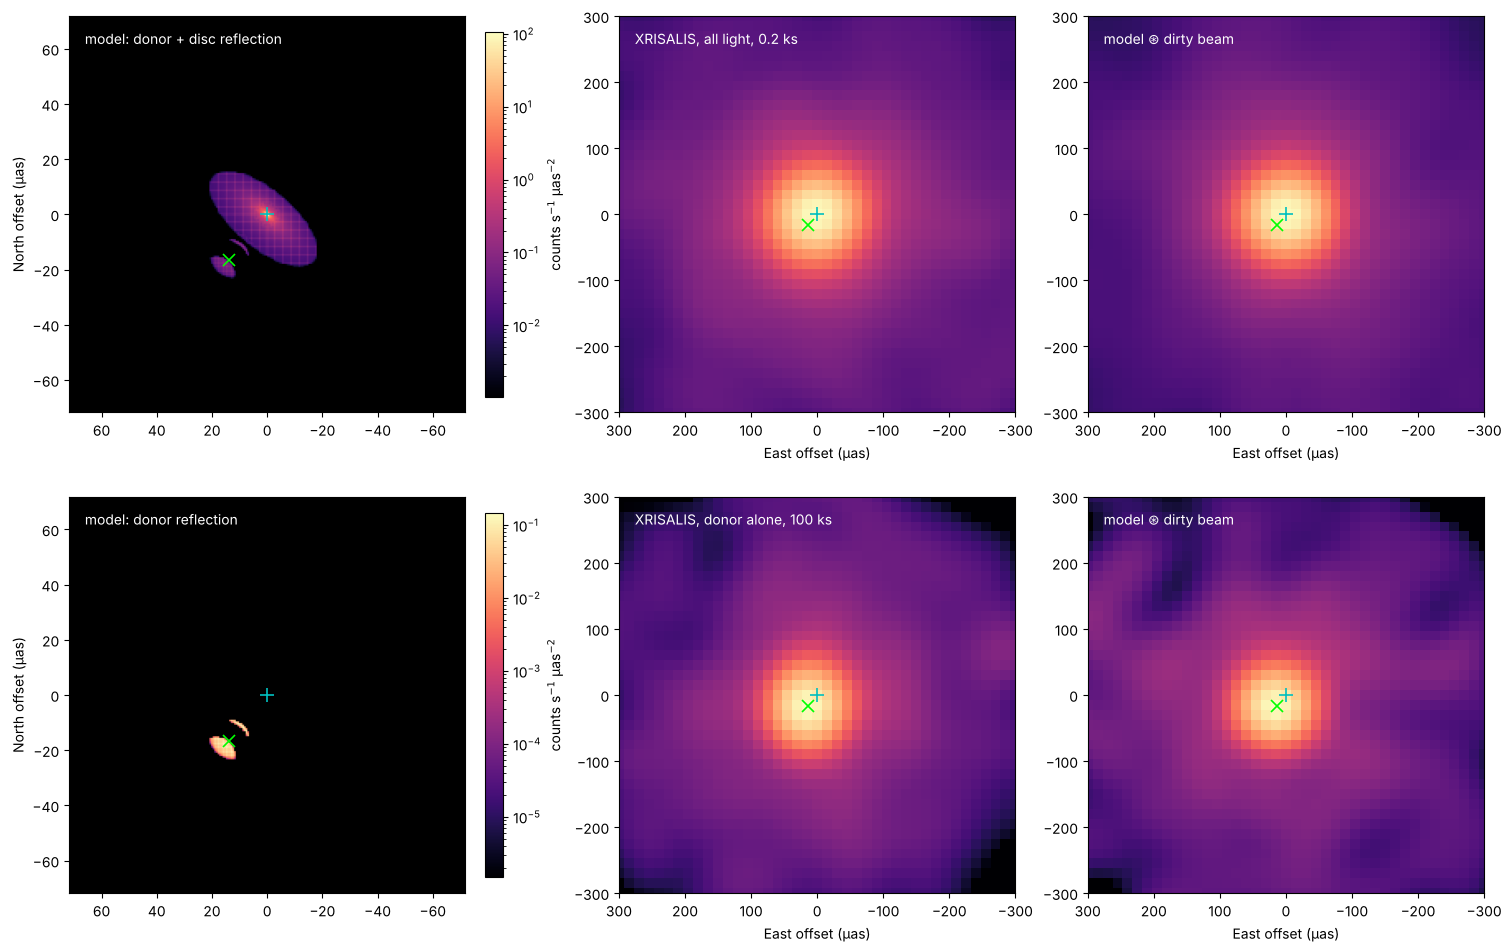

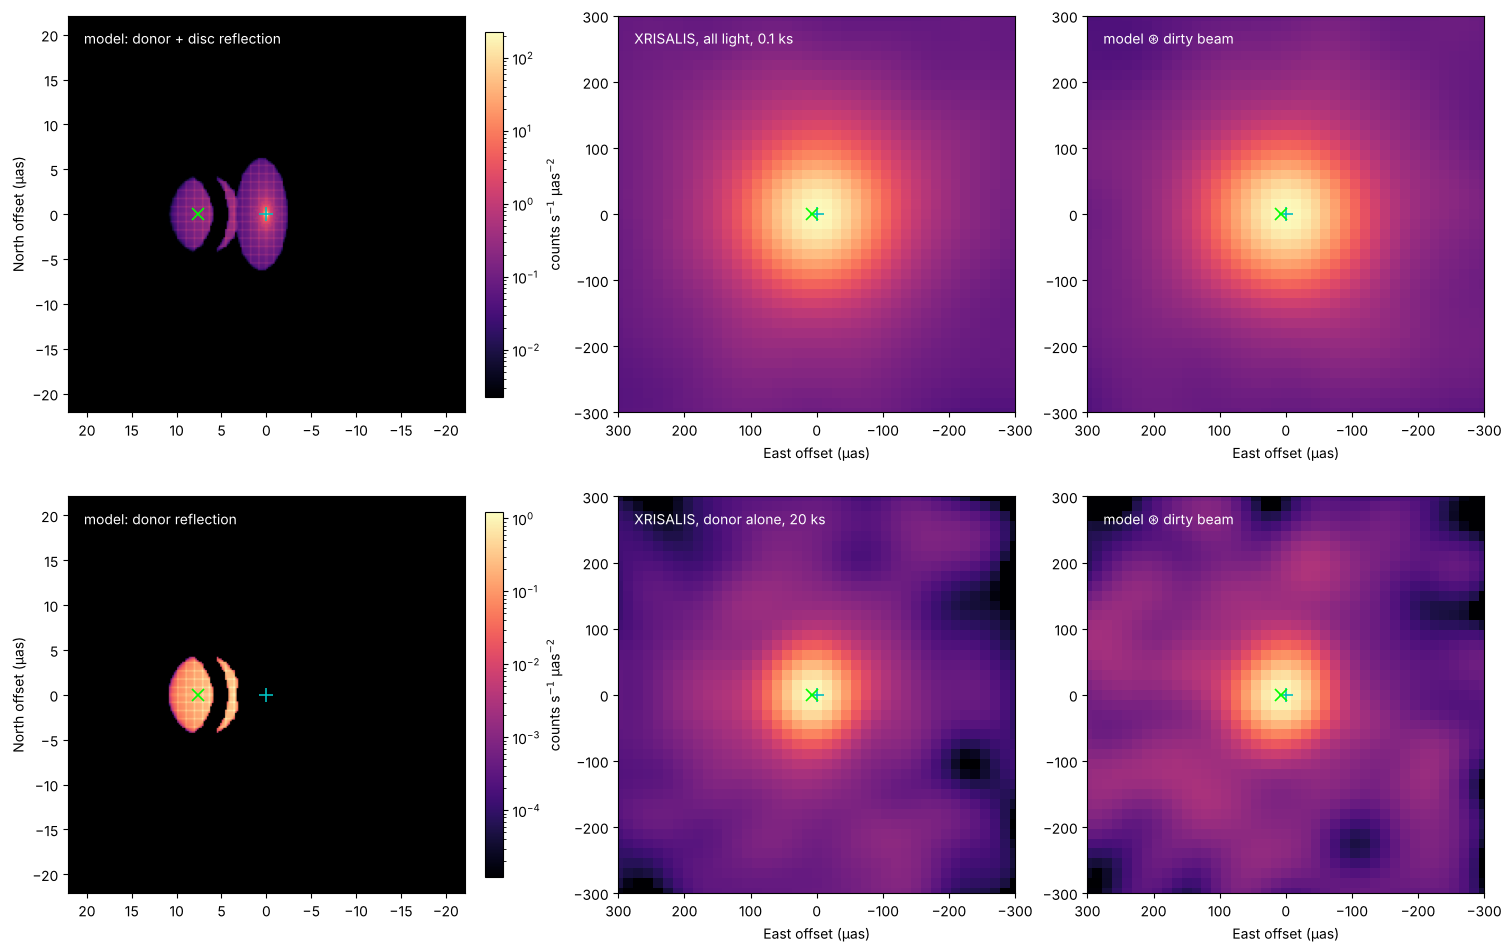

In [5]:
from matplotlib.colors import LogNorm

from lmxrbs_xri.images import surface_brightness

PH = 0.5
FOV = 0.0012  # arcsec
EXPOSURE = {"grs": (200.0, 1e5), "cx2": (100.0, 2e4)}  # s: all light, donor alone
reflected = lambda name: name.endswith(("_star", "_disc"))
donor_only = lambda name: name.endswith("_star")


def centroid(img, span):
    # centroid of the pixels above half the peak (uas, East and North)
    n = img.shape[0]
    c = (np.arange(n) - n / 2) * span / n   # reconstruction pixels: East = +, pixel n/2 at 0
    w = np.where(img > 0.5 * img.max(), img, 0.0)
    return (w.sum(0) @ c) / w.sum(), (w.sum(1) @ c) / w.sum()


sky = {}
for t in TARGETS:
    m = models[t.name][PH]
    s = t.scales()
    half = 1.3 * (s["donor_offset_uas"] + s["r_donor_uas"])
    zoom = xm.RegularGrid(nx=240, ny=240, scale=2 * half / 240)
    dx, dy = t.donor_sky(PH)
    fig, ax = plt.subplots(2, 3, figsize=(15, 9.6), constrained_layout=True)
    for row, (keep, lab, t_exp) in enumerate(((lambda n: True, "all light", EXPOSURE[t.name][0]),
                                               (donor_only, "donor alone", EXPOSURE[t.name][1]))):
        img = surface_brightness(m, zoom, layers=reflected if row == 0 else donor_only)
        v = img.max()
        a = ax[row, 0]
        a.set_facecolor("k")
        im = a.imshow(np.where(img > 0, img, np.nan), origin="lower", extent=[half, -half, -half, half],
                      cmap="magma", norm=LogNorm(v * 1e-5, v))
        a.text(0.04, 0.93, "model: " + ("donor + disc reflection" if row == 0 else "donor reflection"),
               transform=a.transAxes, color="w")
        fig.colorbar(im, ax=a, fraction=0.046, label="counts s$^{-1}$ µas$^{-2}$")
        sub = recipes.subset(m, keep)
        obs = recipes.observe(sub, t_exp, FOV, seed=10 + row)
        flux = sum(L.mean_photon_flux() for L in sub.layers)
        # a third as many photons as the source: enough for a smooth beam, and it fits in memory
        beam = recipes.dirty_beam(obs, t_exp, total_flux=flux / 3)
        n, pix = obs["image"].shape[0], obs["span"] / obs["image"].shape[0]
        g = xm.RegularGrid(nx=n + 1, ny=n + 1, scale=pix)   # odd: pixel centres on the reconstruction's
        pred = recipes.predicted(recipes.model_image(sub, g), (n + 1) / 2 * pix, obs, beam)
        recipes.show(ax[row, 1], obs, lim=300, label=f"XRISALIS, {lab}, {t_exp / 1e3:g} ks")
        recipes.show(ax[row, 2], {"image": pred, "span": obs["span"]}, lim=300, label="model ⊛ dirty beam")
        sky[(t.name, row)] = (len(obs["events"]), centroid(obs["image"], obs["span"]),
                              centroid(pred, obs["span"]))
        del obs, sub  # the event lists are large
        for a in ax[row]:
            a.plot(0, 0, "+", color="c", ms=10, mew=1.2)
            a.plot(dx, dy, "x", color="lime", ms=8, mew=1.2)
        ax[row, 0].set_ylabel("North offset (µas)")
    x, y, r = recipes.pixel_rates(m.layer(f"{t.name}_star"))
    print(f"{t.label}: donor centre ({dx:.1f}, {dy:.1f}) uas, its reflection centred at "
          f"({np.sum(r * x) / r.sum():.1f}, {np.sum(r * y) / r.sum():.1f}) uas")
    for row, lab in enumerate(("all light", "donor alone")):
        ne, c_obs, c_pred = sky[(t.name, row)]
        print(f"  {lab}: {ne} events; peak centroid ({c_obs[0]:.0f}, {c_obs[1]:.0f}) uas "
              f"reconstructed, ({c_pred[0]:.0f}, {c_pred[1]:.0f}) uas predicted")

Neither system is resolved. With all the light, the image is the corona's dirty beam: the reflected light is a few per cent of it, and mostly the disc's, at the compact object. The donor's reflection alone also reconstructs as one beam-sized blob, but centred on the donor: its peak lies within a few µas of where the model puts the reflection (printed above), well inside a 15 µas pixel, as the model convolved with the dirty beam predicts. So the donor's position is in the data as a centroid shift, but only of the donor's own photons: in a real observation the corona's outnumber them ~300 times (Cyg X-2) to ~3000 times (GRS 1915+105), and the centroid of all the light moves by only ~0.02 and ~0.01 µas. The echo below needs no such astrometry. The right-hand panels are a little noisier than the reconstructions because their dirty beam was made with a third as many photons (to fit in memory).

## Response functions

Here we show the Fe-band response of the driven light in counts per second per second of delay through the bundled ARF: the donor's echo moves from a few seconds after the direct light at phase 0 to its maximum at phase 0.5, while the disc's response stays put. The direct light (at zero delay) is off the scale.

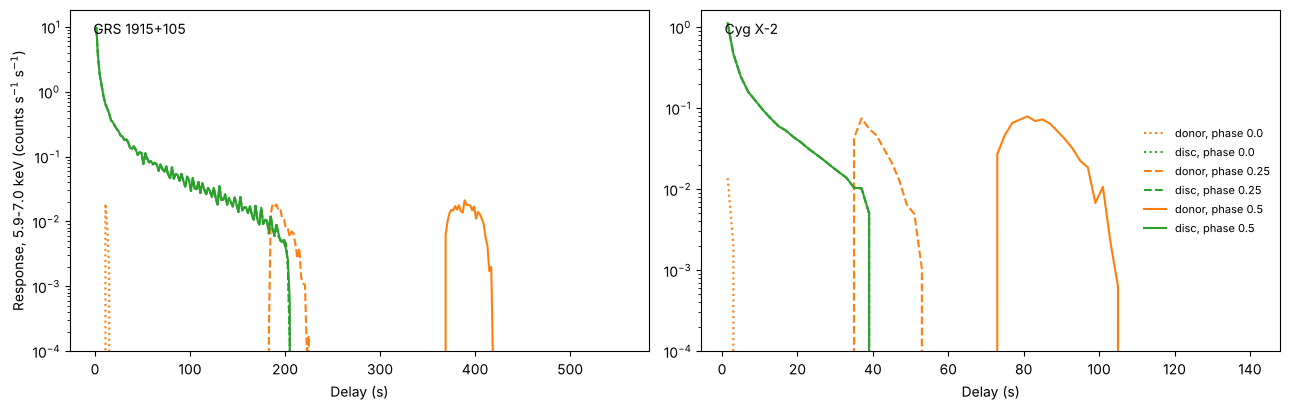

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, t in zip(ax, TARGETS):
    dt = 2.0
    de = np.concatenate([[0, 0.5 * dt], np.arange(dt, 1.2 * 2 * t.scales()["a_light_s"], dt)])
    for ph, ls in ((0.0, ":"), (0.25, "--"), (0.5, "-")):
        m = models[t.name][ph]
        for name, col in (("star", "C1"), ("disc", "C2")):
            psi = xm.transfer_function(m.layer(f"{t.name}_{name}"), np.linspace(*FE, 23), de)
            e_c = np.linspace(*FE, 23)
            r = (psi * area(0.5 * (e_c[1:] + e_c[:-1]))[:, None]).sum(axis=0) / np.diff(de)
            a.semilogy(0.5 * (de[1:] + de[:-1])[1:], r[1:], ls=ls, color=col,
                       label=f"{'donor' if name == 'star' else 'disc'}, phase {ph}")
    a.set_xlabel("Delay (s)")
    a.text(0.04, 0.93, t.label, transform=a.transAxes)
    a.set_ylim(1e-4, None)
ax[0].set_ylabel(f"Response, {FE[0]}-{FE[1]} keV (counts s$^{{-1}}$ s$^{{-1}}$)")
ax[1].legend(frameon=False, fontsize=8, loc="center right")
fig.tight_layout()

## The corona's variability

The echo can only be seen if the corona varies on timescales of the delay or longer. Here we show the power spectra we drive the coronae with: for GRS 1915+105 two broad zero-centred Lorentzians (17% rms between 10 µHz and 4 Hz), and for Cyg X-2 the very-low-frequency noise of the lower normal branch at the high (4.5% rms, index 1.6) and medium (1% rms, index 1.0, plus a 5.5 Hz normal-branch QPO) intensity levels of Wijnands et al. (1997), realised above 1 mHz only. Vertical lines mark 1/(2π τ) for the donor's largest delay.

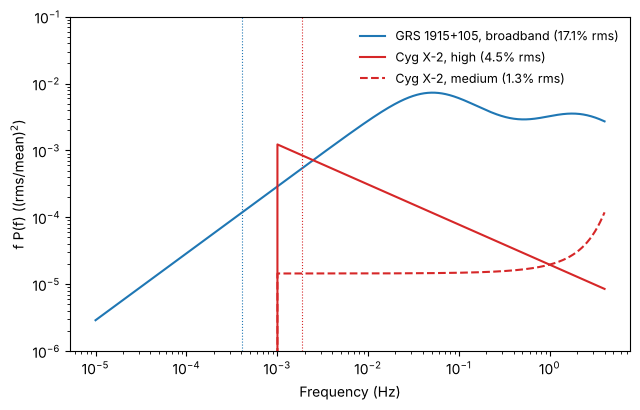

In [7]:
f = np.geomspace(1e-5, 4.0, 1000)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for t, col in zip(TARGETS, ("C0", "C3")):
    for (name, v), ls in zip(t.variability.items(), ("-", "--")):
        ax.loglog(f, f * v.psd(f), ls=ls, color=col, label=f"{t.label}, {name} ({100 * v.rms():.1f}% rms)")
    ax.axvline(1 / (2 * np.pi * orbit[t.name][:, 3].max()), color=col, lw=0.8, ls=":")
ax.set_ylim(1e-6, 1e-1)
ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("f P(f) ((rms/mean)$^2$)")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()

## The echo in the cross-correlation function

Here we show the cross-correlation between the reference band and the Fe band expected from these models (`timing.predicted_ccf`: a linear response to the driver, with Poisson noise for the bundled ARF's count rates, from 1000 s segments in 2 s bins for Cyg X-2 and 4 s bins for GRS 1915+105). The direct light dominates the peak at zero lag; the donor's echo is the small shoulder that moves with phase, so we also show the difference between phases 0.5 and 0. The grey bands are ±1/√N for 100 ks and 1 Ms, a rough guide to the error per lag (neighbouring lags are strongly correlated).

GRS 1915+105: echo difference 0.0020 at 392 s; 1/sqrt(N) = 0.0063 per lag for 100 ks
Cyg X-2: echo difference 0.0052 at 84 s; 1/sqrt(N) = 0.0045 per lag for 100 ks


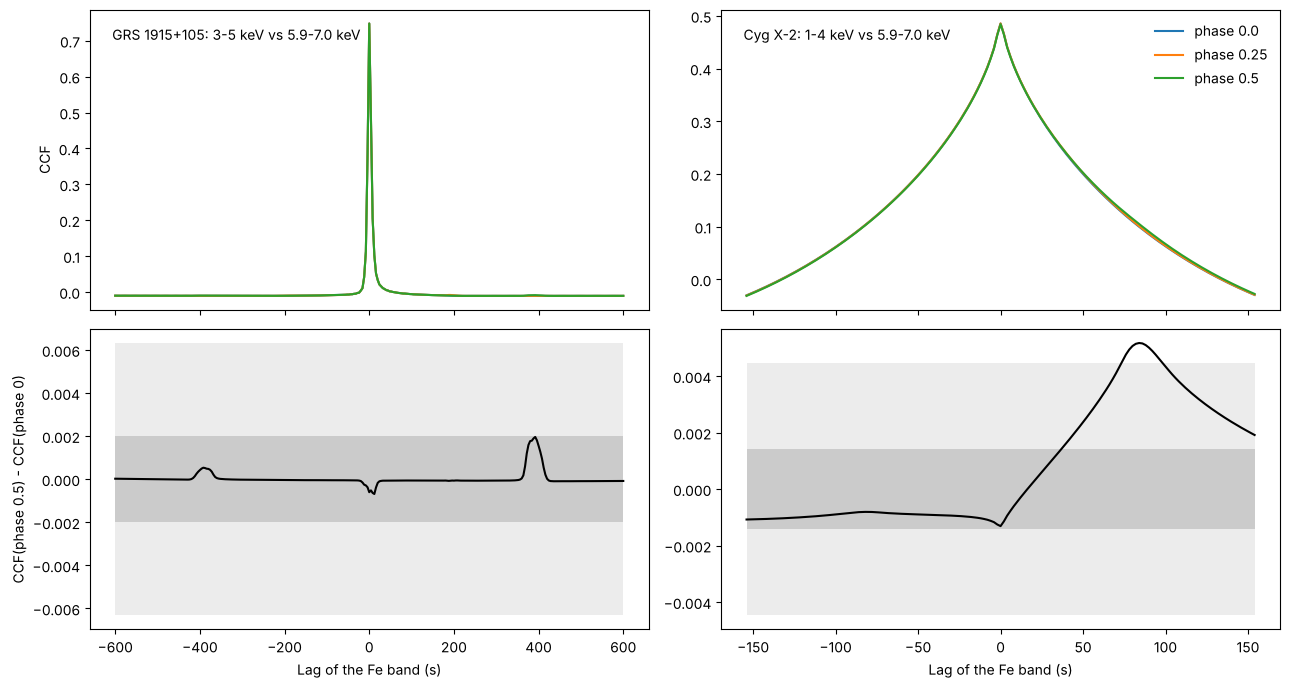

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(13, 7), sharex="col")
summary = {}
for j, t in enumerate(TARGETS):
    v = t.variability[VAR[t.name]]
    dt = 2.0 if t.name == "cx2" else 4.0
    max_lag = int(1.3 * 2 * t.scales()["a_light_s"] / dt)
    de = np.concatenate([[0, 0.5 * dt], np.arange(dt, (max_lag + 2) * dt, dt)])
    ccfs = {}
    for ph in (0.0, 0.25, 0.5):
        m = models[t.name][ph]
        rx, ry = band_rates(m, REF[t.name], area, de), band_rates(m, FE, area, de)
        lags, c = predicted_ccf(v.psd, (rx[0], ry[0]), (rx[1], ry[1]), (rx[2], ry[2]),
                                (rx[3], ry[3]), dt, int(1000 / dt), max_lag)
        ccfs[ph] = c
        ax[0, j].plot(lags * dt, c, label=f"phase {ph}")
    diff = ccfs[0.5] - ccfs[0.0]
    ax[1, j].plot(lags * dt, diff, "k")
    for t_exp, alpha in ((1e5, 0.15), (1e6, 0.3)):
        e1 = 1 / np.sqrt(t_exp / dt)
        ax[1, j].fill_between(lags * dt, -e1, e1, color="0.5", alpha=alpha, lw=0)
    summary[t.label] = (diff.max(), lags[np.argmax(diff)] * dt, 1 / np.sqrt(1e5 / dt))
    ax[0, j].text(0.04, 0.9, f"{t.label}: {REF[t.name][0]:g}-{REF[t.name][1]:g} keV vs {FE[0]}-{FE[1]} keV",
                  transform=ax[0, j].transAxes)
    ax[1, j].set_xlabel("Lag of the Fe band (s)")
ax[0, 0].set_ylabel("CCF"); ax[1, 0].set_ylabel("CCF(phase 0.5) - CCF(phase 0)")
ax[0, 1].legend(frameon=False)
fig.tight_layout()
for k, (d, lag, e1) in summary.items():
    print(f"{k}: echo difference {d:.4f} at {lag:.0f} s; 1/sqrt(N) = {e1:.4f} per lag for 100 ks")

The echo is there but weak: with the bundled array's few hundred cm² in the Fe band, the phase 0.5 minus phase 0 difference is about one 1/√N per lag for 100 ks of Cyg X-2 at its high level, and a third of that for GRS 1915+105, whose corona is mostly direct light in the reference band and whose disc's echo dominates the response out to ~200 s. Fitting the whole shoulder (many correlated lags) at several phases at once does better than one lag; the next notebooks simulate light curves through the instrument and turn this into exposure times.

Caveats: the thermal disc neither varies nor illuminates here, the prompt broad Fe line is constant, Cyg X-2's Comptonised illuminator has an approximate reflection spectrum (not pexmon), and the response is linear in the driver (the realised light curves are log-normal, which matters little at these rms).